# Predicting Crime Severity in LA with Crime Attributes

Members: Carmel Norris (group leader), Alicia Ellis, Sayhan Khan, Lindsey Duffner, Navaj Sivakumar

#### Goal: 
Predict crime severity (part 1 (serious) or part 2 (not very serious)) from various crime attributes (where, when, premise type, weapon, etc.) using Los Angeles Crime Data from 2020 to 2023.

[Link to Dataset](https://www.kaggle.com/datasets/asaniczka/crimes-in-los-angeles-2020-2023?resource=download)

## Exploring the Data

In [68]:
import pandas as pd

df = pd.read_csv('Crime_Data_from_2020_to_Present.csv')

display(df.head())

,division_number,date_reported,date_occurred,area,area_name,reporting_district,part,crime_code,crime_description,modus_operandi,...,status,status_description,crime_code_1,crime_code_2,crime_code_3,crime_code_4,location,cross_street,latitude,longitude
0,10304468,2020-01-08,2020-01-08 22:30:00,3,Southwest,377,2,624,BATTERY - SIMPLE ASSAULT,0444 0913,...,AO,Adult Other,624.0,NaN,NaN,NaN,1100 W 39TH PL,NaN,34.0141,-118.2978
1,190101086,2020-01-02,2020-01-01 03:30:00,1,Central,163,2,624,BATTERY - SIMPLE ASSAULT,0416 1822 1414,...,IC,Invest Cont,624.0,NaN,NaN,NaN,700 S HILL ST,NaN,34.0459,-118.2545
2,200110444,2020-04-14,2020-02-13 12:00:00,1,Central,155,2,845,SEX OFFENDER REGISTRANT OUT OF COMPLIANCE,1501,...,AA,Adult Arrest,845.0,NaN,NaN,NaN,200 E 6TH ST,NaN,34.0448,-118.2474
3,191501505,2020-01-01,2020-01-01 17:30:00,15,N Hollywood,1543,2,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 1402,...,IC,Invest Cont,745.0,998.0,NaN,NaN,5400 CORTEEN PL,NaN,34.1685,-118.4019
4,191921269,2020-01-01,2020-01-01 04:15:00,19,Mission,1998,2,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",0329,...,IC,Invest Cont,740.0,NaN,NaN,NaN,14400 TITUS ST,NaN,34.2198,-118.4468


In [69]:
df.shape

(852950, 27)

In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 852950 entries, 0 to 852949
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   division_number      852950 non-null  int64  
 1   date_reported        852950 non-null  str    
 2   date_occurred        852950 non-null  str    
 3   area                 852950 non-null  int64  
 4   area_name            852950 non-null  str    
 5   reporting_district   852950 non-null  int64  
 6   part                 852950 non-null  int64  
 7   crime_code           852950 non-null  int64  
 8   crime_description    852950 non-null  str    
 9   modus_operandi       734639 non-null  str    
 10  victim_age           852950 non-null  int64  
 11  victim_sex           740344 non-null  str    
 12  victim_descent       740336 non-null  str    
 13  premise_code         852940 non-null  float64
 14  premise_description  852432 non-null  str    
 15  weapon_code          296748 

In [71]:
df.isnull().sum()

division_number             0
date_reported               0
date_occurred               0
area                        0
area_name                   0
reporting_district          0
part                        0
crime_code                  0
crime_description           0
modus_operandi         118311
victim_age                  0
victim_sex             112606
victim_descent         112614
premise_code               10
premise_description       518
weapon_code            556202
weapon_description     556202
status                      0
status_description          0
crime_code_1               11
crime_code_2           790429
crime_code_3           850837
crime_code_4           852888
location                    0
cross_street           717289
latitude                    0
longitude                   0
dtype: int64

In [72]:
df.duplicated().sum()

np.int64(0)

In [73]:
df.describe()

,division_number,area,reporting_district,part,crime_code,victim_age,premise_code,weapon_code,crime_code_1,crime_code_2,crime_code_3,crime_code_4,latitude,longitude
count,8.529500e+05,852950.000000,852950.000000,852950.000000,852950.000000,852950.000000,852940.000000,296748.000000,852939.000000,62521.000000,2113.000000,62.000000,852950.000000,852950.000000
mean,2.166969e+08,10.707354,1117.165490,1.412575,500.746338,29.742191,305.974292,363.225141,500.486350,957.630028,983.847137,990.983871,33.983232,-118.040106
std,1.100081e+07,6.097178,609.716073,0.492298,207.705242,21.799470,216.950442,123.685519,207.493864,111.237318,52.526227,27.477259,1.756263,6.089068
min,8.170000e+02,1.000000,101.000000,1.000000,110.000000,-3.000000,101.000000,101.000000,110.000000,210.000000,310.000000,821.000000,0.000000,-118.667600
25%,2.102184e+08,6.000000,615.000000,1.000000,331.000000,5.000000,101.000000,310.000000,331.000000,998.000000,998.000000,998.000000,34.014100,-118.429700
50%,2.202184e+08,11.000000,1141.000000,1.000000,442.000000,31.000000,203.000000,400.000000,442.000000,998.000000,998.000000,998.000000,34.058500,-118.321500
75%,2.301094e+08,16.000000,1617.000000,2.000000,626.000000,45.000000,501.000000,400.000000,626.000000,998.000000,998.000000,998.000000,34.163200,-118.273900
max,2.399306e+08,21.000000,2199.000000,2.000000,956.000000,120.000000,976.000000,516.000000,956.000000,999.000000,999.000000,999.000000,34.334300,0.000000


In [74]:
leak_cols = ['crime_code', 'crime_description', 'modus_operandi', 'crime_code_1', 'crime_code_2', 'crime_code_3', 'crime_code_4']
df = df.drop(columns=leak_cols)

In [75]:
irrel_cols = ['division_number', 'location', 'cross_street']
df = df.drop(columns=irrel_cols)

In [76]:
dup_cols = ['date_reported', 'area', 'premise_code', 'weapon_code', 'status']
df = df.drop(columns=dup_cols)

print(df.shape)
print(df.isnull().sum())

(852950, 12)
date_occurred               0
area_name                   0
reporting_district          0
part                        0
victim_age                  0
victim_sex             112606
victim_descent         112614
premise_description       518
weapon_description     556202
status_description          0
latitude                    0
longitude                   0
dtype: int64


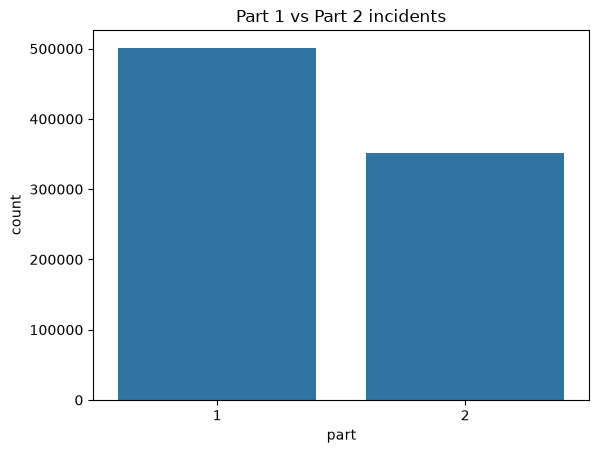

In [77]:
import seaborn as sns
import matplotlib.pyplot as plt

# class imbalance
sns.countplot(data=df, x='part')
plt.title("Part 1 vs Part 2 incidents")
plt.show()


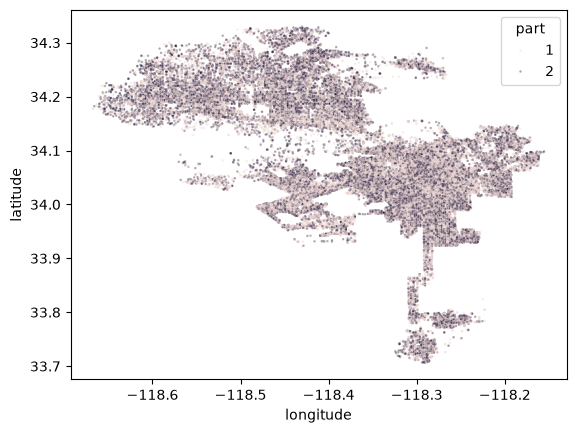

In [78]:
# map showing crime location
s = df.sample(100_000, random_state=42).copy()

g = s[s["latitude"] != 0]
sns.scatterplot(data=g, x="longitude", y="latitude", hue="part", s=3, alpha=0.4)
plt.show()

In [79]:
# feature engineering: turn date occurred into 3 columns: hour, day of the week, and month
d = pd.to_datetime(df["date_occurred"])
df["hour"], df["dayofweek"], df["month"] = d.dt.hour, d.dt.dayofweek, d.dt.month

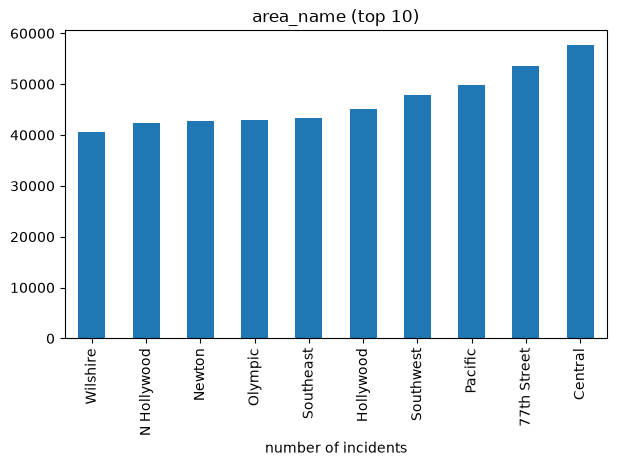

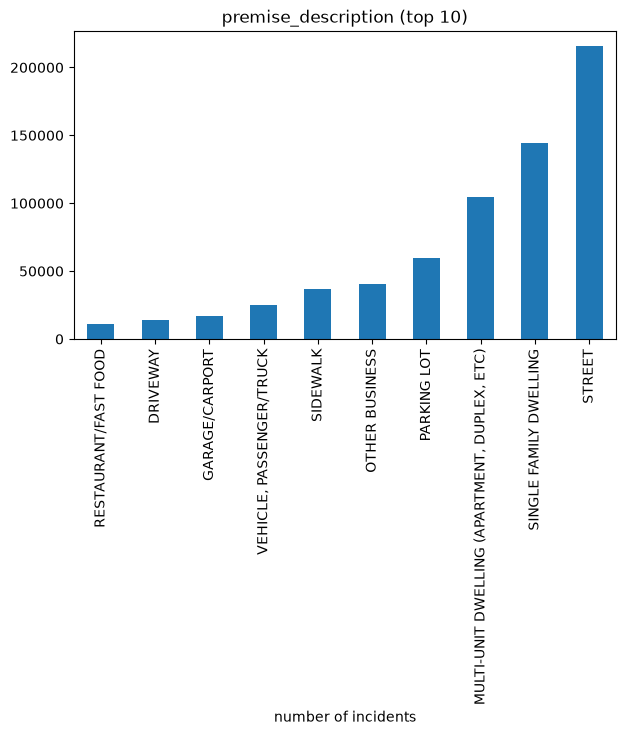

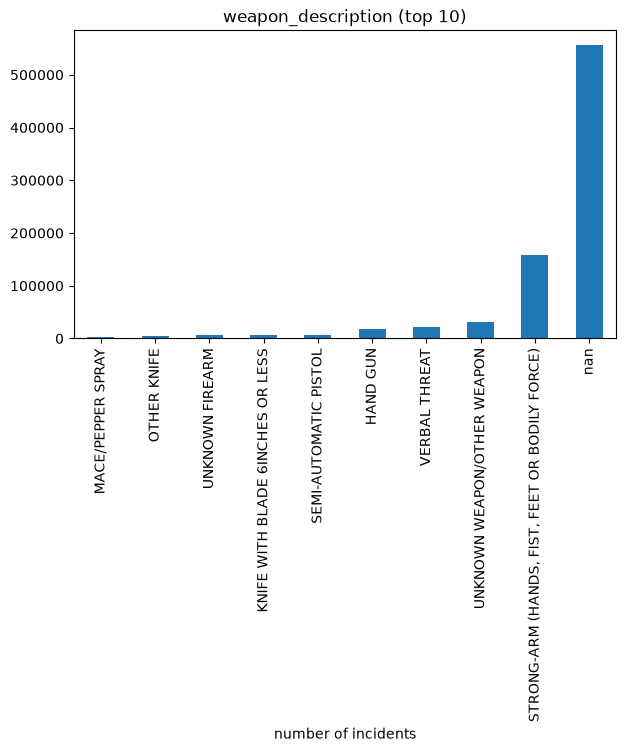

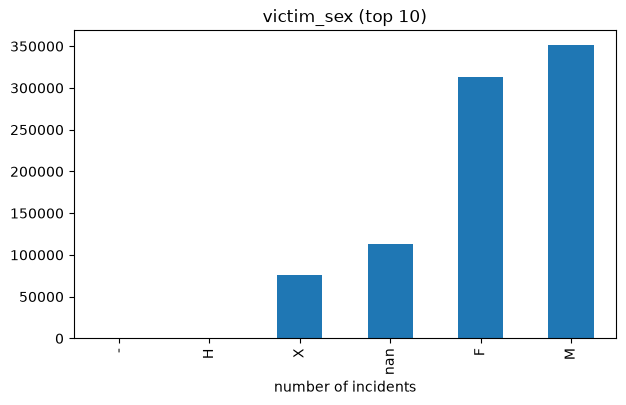

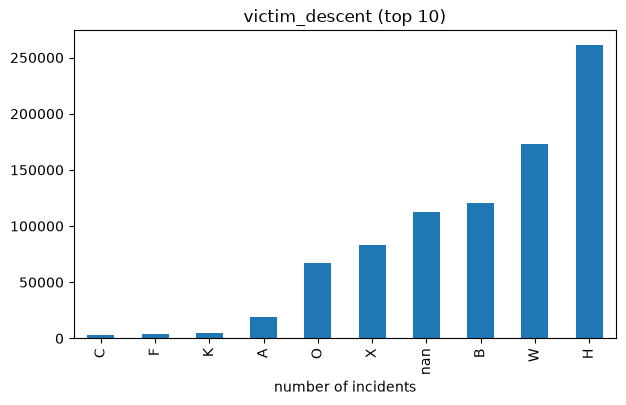

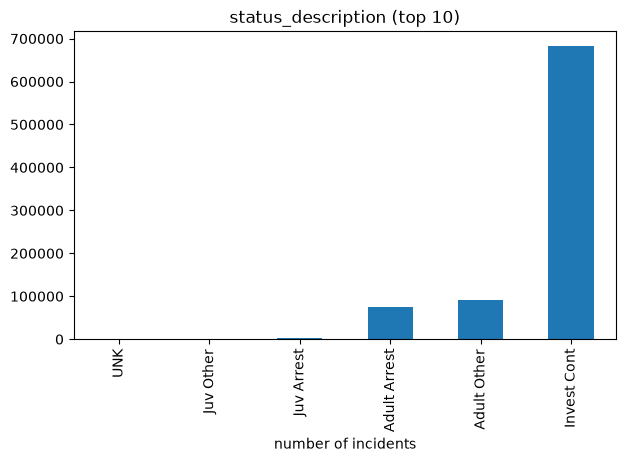

In [80]:
def bar(col, top=10):
    df[col].value_counts(dropna=False).head(top).sort_values().plot(
        kind="bar", figsize=(7, 4), title=f"{col} (top {top})")
    plt.xlabel("number of incidents")
    plt.show()

for c in ["area_name", "premise_description", "weapon_description",
          "victim_sex", "victim_descent", "status_description"]:
    bar(c)

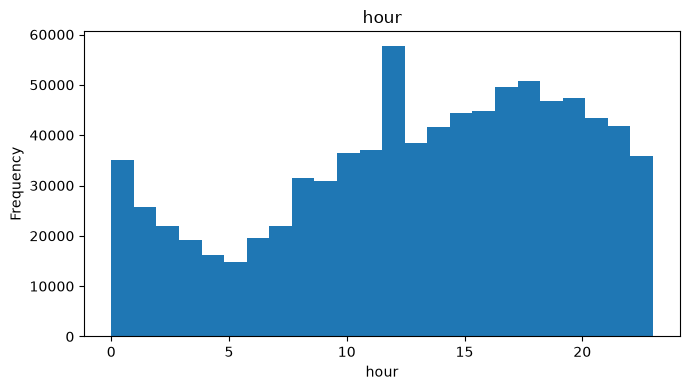

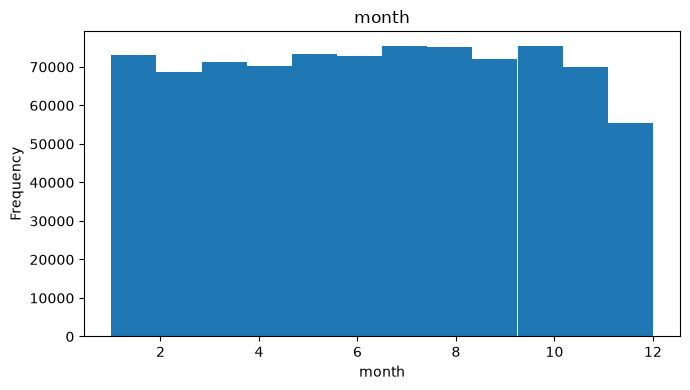

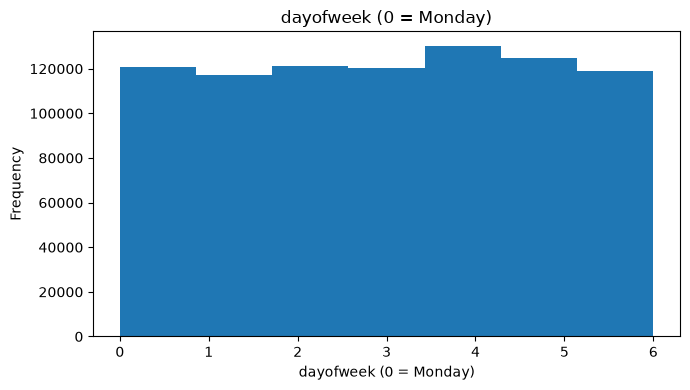

In [81]:
def hist(series, title, bins=30):
    series.plot(kind="hist", bins=bins, figsize=(7, 4), title=title)
    plt.xlabel(title)
    plt.tight_layout()
    plt.show()
    
hist(df["hour"], "hour", bins=24)
hist(df["month"], "month", bins=12)
hist(df["dayofweek"], "dayofweek (0 = Monday)", bins=7)

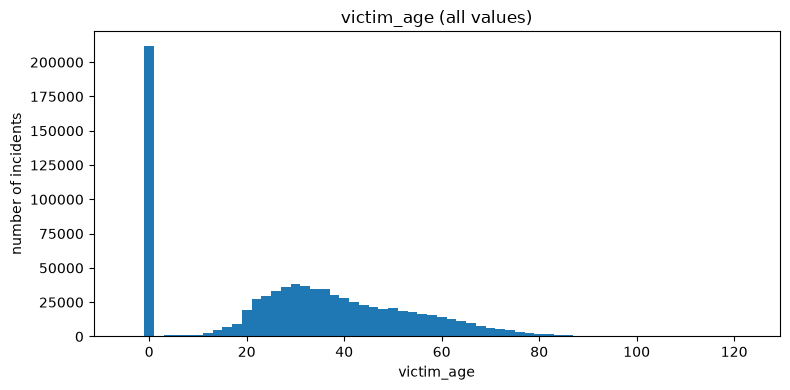

In [82]:
df["victim_age"].plot(kind="hist", bins=range(-5, 125, 2), figsize=(8, 4),
                      title="victim_age (all values)")
plt.xlabel("victim_age")
plt.ylabel("number of incidents")
plt.tight_layout()
plt.show()

In [83]:
import numpy as np

# labeling fixes

# 0 or negative age -> age missing
df['age_missing'] = (df['victim_age'] <= 0).astype(int)
df.loc[df['victim_age'] <= 0, 'victim_age'] = np.nan

# null values -> missing; strange values -> unknown
df['victim_sex'] = df['victim_sex'].fillna('MISSING')
df['victim_sex'] = df['victim_sex'].replace({
    'X': 'UNKNOWN',
    'H': 'UNKNOWN',
    '-': 'UNKNOWN'
})

# null values -> missing; strange values -> unknown
df['victim_descent'] = df['victim_descent'].fillna('MISSING')
df['victim_descent'] = df['victim_descent'].replace({
    'X': 'UNKNOWN',
    '-': 'UNKNOWN',
})

# blank for weapon description -> no weapon recorded
df['weapon_description'] = df['weapon_description'].fillna('NONE')

# blank for premise description -> unknown
df['premise_description'] = df['premise_description'].fillna('UNKNOWN')

# handling 0s in long/lat
df.loc[df["latitude"] == 0, ["latitude", "longitude"]] = np.nan

In [84]:
print(df.isnull().sum())

date_occurred               0
area_name                   0
reporting_district          0
part                        0
victim_age             211916
victim_sex                  0
victim_descent              0
premise_description         0
weapon_description          0
status_description          0
latitude                 2263
longitude                2263
hour                        0
dayofweek                   0
month                       0
age_missing                 0
dtype: int64


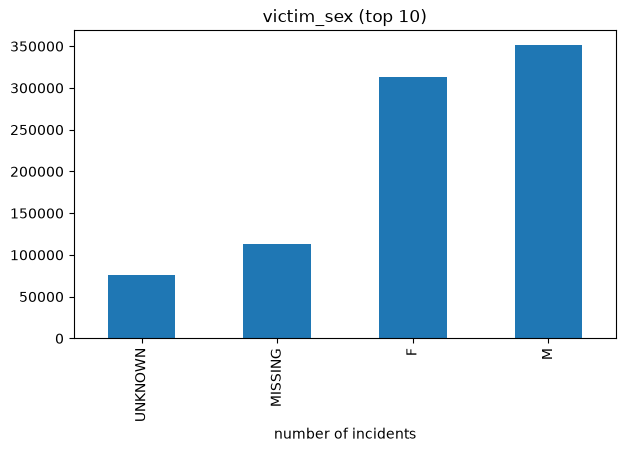

In [85]:
bar('victim_sex')

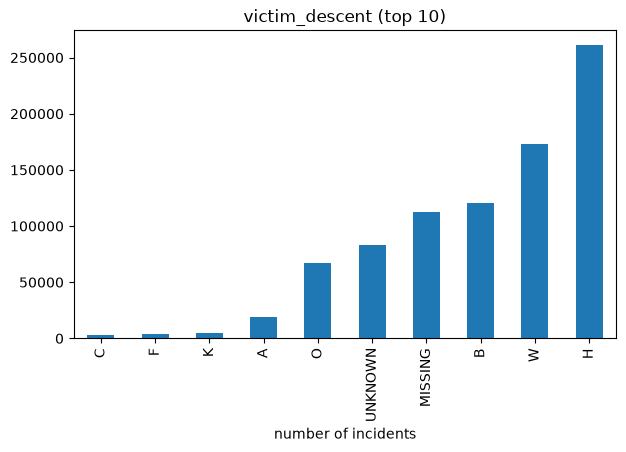

In [86]:
bar('victim_descent')

In [87]:
df['victim_age'].describe()

count    641034.000000
mean         39.574642
std          15.594740
min           2.000000
25%          28.000000
50%          37.000000
75%          50.000000
max         120.000000
Name: victim_age, dtype: float64

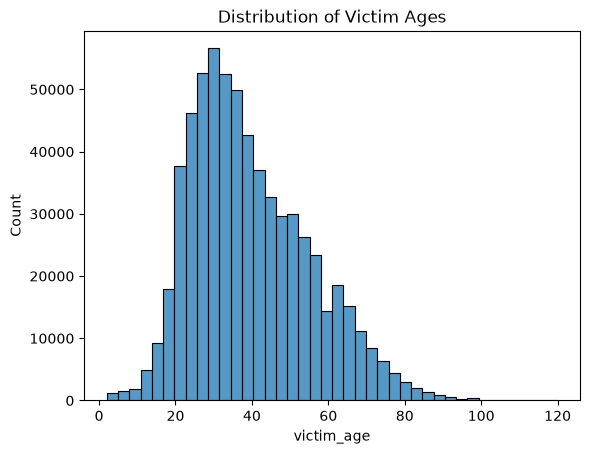

In [88]:
sns.histplot(df['victim_age'], bins=40)
plt.title('Distribution of Victim Ages')
plt.show()

In [89]:
# drop the records with 0 as longitude and latitude
df = df.dropna()
print(df.isnull().sum())

date_occurred          0
area_name              0
reporting_district     0
part                   0
victim_age             0
victim_sex             0
victim_descent         0
premise_description    0
weapon_description     0
status_description     0
latitude               0
longitude              0
hour                   0
dayofweek              0
month                  0
age_missing            0
dtype: int64


Lower Bound: -5.0
Upper Bound: 83.0
Number of potential outliers for victim age: 3865


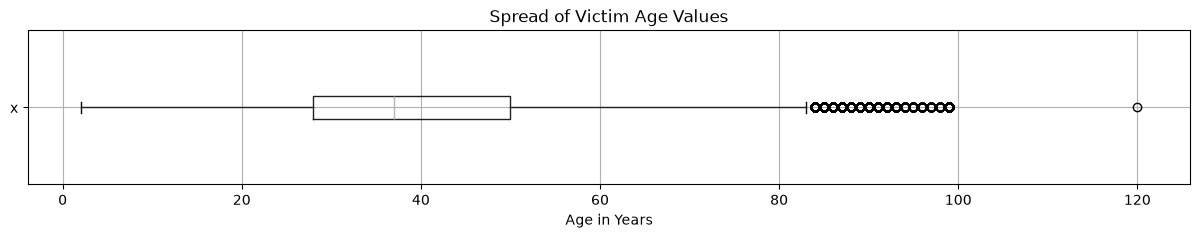

In [90]:
import pandas.plotting as pd_plotting
# find outliers with IQR method

# victim age:
ages = df.loc[df['age_missing'] == 0, 'victim_age']

va_Q1 = ages.quantile(0.25)
va_Q3 = ages.quantile(0.75)
va_IQR = va_Q3 - va_Q1

va_lower_bound = va_Q1 - 1.5 * va_IQR
va_upper_bound = va_Q3 + 1.5 * va_IQR

va_outliers = ages[
    (ages < va_lower_bound) |
    (ages > va_upper_bound)
]
print("Lower Bound:", va_lower_bound)
print("Upper Bound:", va_upper_bound)
print("Number of potential outliers for victim age:", len(va_outliers))

pd_plotting.boxplot(ages, figsize=(15, 2), vert=False)
plt.title("Spread of Victim Age Values")
plt.xlabel("Age in Years")
plt.show()

Lower Bound: 33.790400000000005
Upper Bound: 34.3904
Number of potential outliers for latitude: 17966


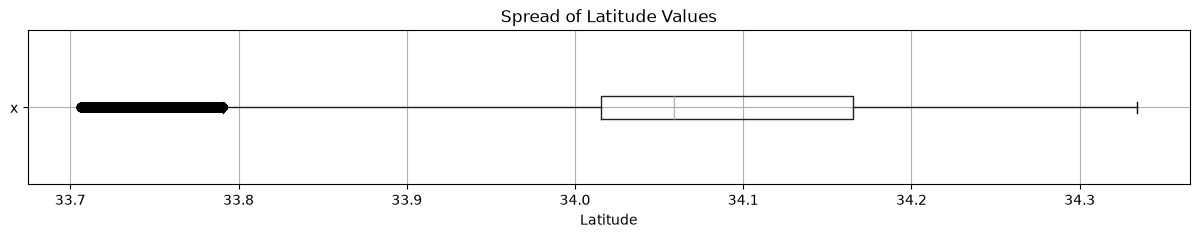

In [91]:
# finding outliers for latitude

lat_Q1 = df['latitude'].quantile(0.25)
lat_Q3 = df['latitude'].quantile(0.75)
lat_IQR = lat_Q3 - lat_Q1

lat_lower_bound = lat_Q1 - 1.5 * lat_IQR
lat_upper_bound = lat_Q3 + 1.5 * lat_IQR

lat_outliers = df[
    (df['latitude'] < lat_lower_bound) |
    (df['latitude'] > lat_upper_bound)
]
print("Lower Bound:", lat_lower_bound)
print("Upper Bound:", lat_upper_bound)
print("Number of potential outliers for latitude:", len(lat_outliers))

pd_plotting.boxplot(df['latitude'], figsize=(15, 2), vert=False)
plt.title("Spread of Latitude Values")
plt.xlabel("Latitude")
plt.show()

Lower Bound: -118.67025000000002
Upper Bound: -118.03864999999998
Number of potential outliers for longitude: 0


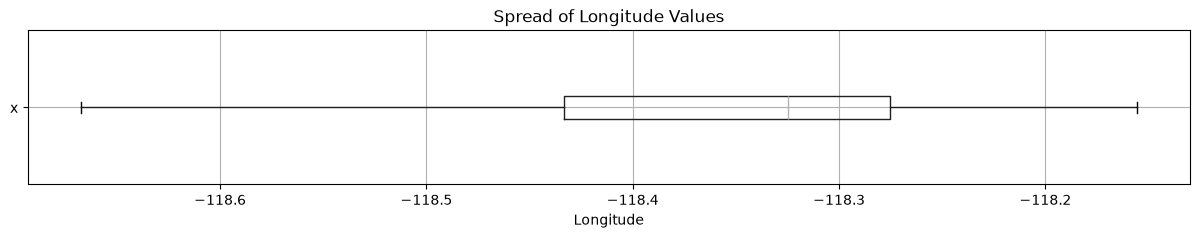

In [92]:
# finding outliers for longitude

long_Q1 = df['longitude'].quantile(0.25)
long_Q3 = df['longitude'].quantile(0.75)
long_IQR = long_Q3 - long_Q1

long_lower_bound = long_Q1 - 1.5 * long_IQR
long_upper_bound = long_Q3 + 1.5 * long_IQR

long_outliers = df[
    (df['longitude'] < long_lower_bound) |
    (df['longitude'] > long_upper_bound)
]
print("Lower Bound:", long_lower_bound)
print("Upper Bound:", long_upper_bound)
print("Number of potential outliers for longitude:", len(long_outliers))

pd_plotting.boxplot(df['longitude'], figsize=(15, 2), vert=False)
plt.title("Spread of Longitude Values")
plt.xlabel("Longitude")
plt.show()

In [93]:
df = df.drop(columns=['status_description', 'date_occurred'])
print(df.shape)
print(df.isnull().sum())

(639329, 14)
area_name              0
reporting_district     0
part                   0
victim_age             0
victim_sex             0
victim_descent         0
premise_description    0
weapon_description     0
latitude               0
longitude              0
hour                   0
dayofweek              0
month                  0
age_missing            0
dtype: int64


In [94]:
# data preparation
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


X = df.drop(columns=['part'])
y = df['part']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# winsorize age
X_train, X_test = X_train.copy(), X_test.copy()
age_cap = X_train['victim_age'].quantile(0.99)
X_train['victim_age'] = X_train['victim_age'].clip(upper=age_cap)
X_test['victim_age'] = X_test['victim_age'].clip(upper=age_cap)

# 100k stratified training subsample so things run quicker
X_tr, _, y_tr, _ = train_test_split(X_train, y_train, train_size=100_000, stratify=y_train, random_state=42)

# feature lists
numerical = ['victim_age', 'latitude', 'longitude', 'hour', 'dayofweek', 'month', 'age_missing']
categorical = ['area_name', 'reporting_district', 'victim_sex', 'victim_descent', 'premise_description', 'weapon_description']
base_features = [c for c in numerical + categorical]

In [95]:
NUM = numerical
CAT = categorical

In [96]:
# preprocessing builder: impute and scale numerical features, encode categorical features
def build_pre(features, min_freq=0.005):
    num = [c for c in features if c in NUM]
    cat = [c for c in features if c in CAT]
    steps = []
    if num:
        steps.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                                       ("sc", StandardScaler())]), num))
    if cat:
        steps.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                           min_frequency=min_freq), cat))
    return ColumnTransformer(steps)

# 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

# evalutaion helper function
def evaluate(name, model, features=base_features, min_freq=0.005):
    pipe = Pipeline([('pre', build_pre(features, min_freq)), ('model', model)])
    r = cross_validate(pipe, X_tr[features], y_tr, cv=cv,
                       scoring=["f1_macro", "accuracy"], return_train_score=True, n_jobs=-1)
    results.append({"model": name, "note": "", "n_features": len(features),
                    "train F1": r["train_f1_macro"].mean(),
                    "CV F1": r["test_f1_macro"].mean(),
                    "CV accuracy": r["test_accuracy"].mean()})
    return pd.DataFrame(results).round(3)


# example use: evaluate("KNN (k=15)", KNeighborsClassifier(n_neighbors=15)) 

## Project Plan

**Problem:** Supervised binary classification. Predict whether a reported LA crime is Part 1 (serious) or Part 2 (lesser) from where, when, and under what circumstances it occurred. One row = one reported incident.

**1. Data preparation**
- Stratified 80/20 train/test split, with the test set untouched until the final evaluation
- Impute missing `victim_age` with the training-set median (the `age_missing` flag preserves the information)
- Winsorize `victim_age` at the training-set 99th percentile
- One-hot encode categorical features (rare premise/weapon categories grouped together)
- Standardize numeric features (needed for logistic regression and KNN, not for tree-based models)
- Class imbalance (59% Part 1 / 41% Part 2): use stratified splits and macro-F1, then compare no adjustment, `class_weight="balanced"`, and SMOTE (applied only within training folds)
- All steps live inside a scikit-learn Pipeline so nothing leaks across folds

**2. Models**
- Baselines: logistic regression, decision tree
- Distance-based: K-Nearest Neighbors
- Ensembles: random forest, gradient boosting, and a stacking ensemble combining the base models
- Models that are slow on 850k rows (KNN, stacking) are trained on a 100k-row sample of the training set

**3. Evaluation**
- Metrics: macro-F1, precision/recall per class, confusion matrix
- Accuracy is compared against the 59% majority-class baseline
- Over/underfitting: compare train vs. 5-fold cross-validation scores for each model; large gaps indicate overfitting (e.g., unpruned decision tree), low scores on both indicate underfitting


**4. Model optimization**
- Grid search with cross-validation on the best 2-3 models
- Feature selection (filter and wrapper methods)
- Class imbalance 

**5. Final evaluation**
- Evaluate the best model once on the held-out test set, then summarize findings and limitations
- Cleanup notebook for presentation

In [97]:
from sklearn.svm import LinearSVC

# Define Linear SVM
svm = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

# Evaluate using the group work
svm_results = evaluate("Linear SVM", svm)

print(svm_results)

        model note  n_features  train F1  CV F1  CV accuracy
0  Linear SVM               13     0.754  0.753        0.753


In [98]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# SVM pipeline using group preprocessing
svm_pipeline = Pipeline([
    ('pre', build_pre(base_features)),
    ('model', LinearSVC(
        max_iter=5000,
        random_state=42
    ))
])

# Test different regularization strengths
param_grid = {
    'model__C': [0.01, 0.1, 1, 10]
}

grid_search = GridSearchCV(
    svm_pipeline,
    param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=2
)

grid_search.fit(X_tr[base_features], y_tr)

print("Best C:", grid_search.best_params_)
print("Best CV F1:", round(grid_search.best_score_, 4))

Best C: {'model__C': 10}
Best CV F1: 0.7533


Final SVM Test Accuracy: 0.752

Final Classification Report:
              precision    recall  f1-score   support

           1       0.77      0.74      0.76     65930
           2       0.74      0.76      0.75     61936

    accuracy                           0.75    127866
   macro avg       0.75      0.75      0.75    127866
weighted avg       0.75      0.75      0.75    127866



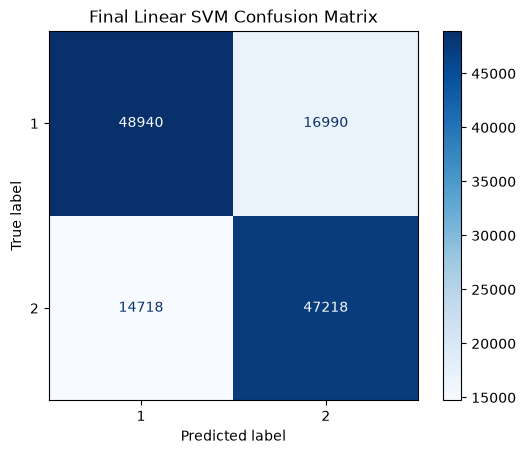

In [103]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict using the final SVM
final_predictions = final_svm.predict(X_test[base_features])

# Final evaluation
print("Final SVM Test Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))

print("\nFinal Classification Report:")
print(classification_report(y_test, final_predictions))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    cmap="Blues",
    values_format="d"
)

plt.title("Final Linear SVM Confusion Matrix")
plt.show()